# Week 10 Project Starter Template: Recommender Pipeline
**Team name:** Book Finder | **Members:** M.Sukanya,B.Gnyanasindhu | **Topic (ID and name):**P02,Book Recommendation System | **Twist (if sharing a topic):** ____________

How to use this: keep the section order, fill every TODO, delete this instruction block when done. AI tools are allowed. Every number you report must come from running this notebook. Sections 12 to 14 are the **understanding pack**, which is what shows the project is yours.

| # | Section | Done |
|---|---|---|
| 1 | Problem and users | [ ] |
| 2 | Data | [ ] |
| 3 | EDA | [ ] |
| 4 | Baselines | [ ] |
| 5 | Content-based model | [ ] |
| 6 | Collaborative model | [ ] |
| 7 | Matrix factorization (SVD) | [ ] |
| 8 | Honest evaluation and results table | [ ] |
| 9 | Cold start or hybrid | [ ] |
| 10 | Demo: recommend() | [ ] |
| 11 | Break-it tests | [ ] |
| 12 | By-hand check | [ ] |
| 13 | Deliberate-leak experiment, decision log, bug log | [ ] |
| 14 | AI-use log | [ ] |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

np.random.seed(1)
pd.set_option('display.precision', 3)


## Helpers (tested, reuse them)
Ratings live in a **long table** with columns `user`, `item`, `rating` and optionally `time`. Rename your own columns to match.

In [ ]:
def split_ratings(df, test_frac=0.2, time_col=None, min_user_ratings=5, seed=1):
    """Split RATINGS (not users) into train and test.
    If time_col is given, each user's most recent test_frac of ratings go to test (time-based split).
    Otherwise a random split. Users with fewer than min_user_ratings ratings stay entirely in train."""
    rng = np.random.RandomState(seed)
    test_idx = []
    for u, g in df.groupby('user'):
        if len(g) < min_user_ratings:
            continue
        n_test = max(1, int(round(test_frac * len(g))))
        if time_col:
            test_idx += list(g.sort_values(time_col).index[-n_test:])
        else:
            test_idx += list(rng.choice(g.index, n_test, replace=False))
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)

def to_matrix(df, users=None, items=None):
    M = df.pivot_table(index='user', columns='item', values='rating', aggfunc='mean')
    if users is not None: M = M.reindex(index=users)
    if items is not None: M = M.reindex(columns=items)
    return M

def rmse(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def precision_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k):
    return len(set(recommended[:k]) & set(relevant)) / max(1, len(relevant))

def ndcg_at_k(recommended, relevant, k):
    gains = [1.0 / np.log2(i + 2) for i, it in enumerate(recommended[:k]) if it in set(relevant)]
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(relevant))))
    return sum(gains) / ideal if ideal > 0 else 0.0

def evaluate_topn(scores, train, test, k=10, rel_threshold=4):
    """scores: DataFrame (users x items) of predicted scores. Relevant = test ratings >= rel_threshold.
    Items the user already has in TRAIN are never recommended. Returns mean precision, recall, NDCG at k."""
    seen = train.groupby('user')['item'].apply(set).to_dict()
    rel = test[test.rating >= rel_threshold].groupby('user')['item'].apply(list).to_dict()
    P, R_, N = [], [], []
    for u, relevant in rel.items():
        if u not in scores.index: continue
        s = scores.loc[u].drop(labels=[i for i in seen.get(u, set()) if i in scores.columns], errors='ignore')
        rec = list(s.sort_values(ascending=False).index)
        P.append(precision_at_k(rec, relevant, k)); R_.append(recall_at_k(rec, relevant, k)); N.append(ndcg_at_k(rec, relevant, k))
    return {'users': len(P), f'precision@{k}': float(np.mean(P)), f'recall@{k}': float(np.mean(R_)), f'ndcg@{k}': float(np.mean(N))}

def svd_scores(R_train, k=10, seed=1):
    """Simple matrix factorization: centre by user mean, fill unrated with 0 (= no opinion), TruncatedSVD, add the mean back.
    A basic version for learning; libraries such as implicit or scikit-surprise are the next step."""
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0).values
    svd = TruncatedSVD(n_components=k, random_state=seed)
    U = svd.fit_transform(C)
    return pd.DataFrame(U @ svd.components_ + means.fillna(means.mean()).values[:, None], index=R_train.index, columns=R_train.columns)


### Smoke test for the helpers (run once, then delete this cell)
Builds a small fake dataset and checks the helpers run. This is **not** your data.

In [ ]:
rng = np.random.RandomState(0)
fake = pd.DataFrame([(f'U{u}', f'I{i}', float(np.clip(round(3 + (1.5 if i % 3 == u % 3 else -1) + rng.normal(0, .5)), 1, 5)), rng.randint(0, 1000))
                     for u in range(40) for i in range(30) if rng.rand() < .4], columns=['user', 'item', 'rating', 'time'])
tr, te = split_ratings(fake, time_col='time')
Rtr = to_matrix(tr, users=sorted(fake.user.unique()), items=sorted(fake.item.unique()))
sc = svd_scores(Rtr, k=5)
pred = [sc.loc[u, i] for u, i in zip(te.user, te.item)]
print('train', len(tr), 'test', len(te), '| SVD RMSE:', round(rmse(pred, te.rating), 3), '| global-mean RMSE:', round(rmse([tr.rating.mean()] * len(te), te.rating), 3))
print(evaluate_topn(sc, tr, te, k=5))


train 362 test 89 | SVD RMSE: 1.247 | global-mean RMSE: 1.303
{'users': 31, 'precision@5': 0.14838709677419357, 'recall@5': 0.6129032258064516, 'ndcg@5': 0.35726080884871414}


## 1. Problem and users
TODO: Who is the user? What is being recommended? What decision does it support? (2 to 4 sentences.)
This project builds a book recommendation system using the Goodbooks-10k dataset. It helps readers discover books they may enjoy based on book information and ratings from other users. The system compares global and book-level baselines with content-based recommendations, collaborative filtering, and matrix factorization. It supports the decision of which books to recommend to a reader.


## 2. Data
TODO: source link, licence, number of users, items and ratings, cleaning steps and why, **sparsity**.

In [ ]:
# TODO: load your data into a long table with columns user, item, rating (and time if you have it)
# df = pd.read_csv(...)
# n_users, n_items, n_ratings = df.user.nunique(), df.item.nunique(), len(df)
# print('sparsity:', 1 - n_ratings / (n_users * n_items))



**Dataset:** Goodbooks-10k Book Recommendation Dataset

**Source:** https://github.com/zygmuntz/goodbooks-10k

The dataset contains book ratings from users and metadata about books. The ratings file contains user IDs, book IDs, and ratings on a scale of 1 to 5. The books file contains information such as book titles, authors, and average ratings.

The original ratings dataset contains 5,976,479 ratings from 53,424 users across 10,000 books. Data quality checks will identify missing values and duplicate user-book ratings. Dataset sparsity will also be calculated to understand how few user-book pairs have ratings compared with all possible pairs.

The dataset licence will be checked in the original repository.


In [ ]:
import os

zip_path = "/content/goodbooks-10k.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("File size:", os.path.getsize(zip_path), "bytes")

    with open(zip_path, "rb") as f:
        print("First 20 bytes:", f.read(20))


File exists: True
File size: 32675160 bytes
First 20 bytes: b'PK\x03\x04\x14\x00\x02\x00\x08\x00zJ-K\xa1`\x93\xd2D\x98'


In [ ]:
import requests
import zipfile
import os

url = "https://github.com/zygmuntz/goodbooks-10k/archive/refs/heads/master.zip"
zip_path = "/content/goodbooks-10k.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Downloaded bytes:", len(response.content))
print("ZIP signature:", response.content[:4])

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/Book_dataset")

print("Extraction complete!")
print("Extracted folders:", os.listdir("/content/Book_dataset"))


Downloaded bytes: 87844319
ZIP signature: b'PK\x03\x04'
Extraction complete!
Extracted folders: ['goodbooks-10k-master']


In [ ]:
import os

data_path = "/content/Book_dataset/goodbooks-10k-master"

print("Files in dataset folder:")
print(os.listdir(data_path))


Files in dataset folder:
['.gitignore', 'book_tags.csv', 'contrib', 'ratings.csv', 'books_xml', 'samples', 'quick_look.ipynb', 'tags.csv', 'README.md', 'THANKS.md', 'to_read.csv', 'books.csv', 'LICENSE']


In [ ]:
import os
import pandas as pd
import numpy as np

data_path = "/content/Book_dataset/goodbooks-10k-master"

ratings = pd.read_csv(os.path.join(data_path, "ratings.csv"))
books_df = pd.read_csv(os.path.join(data_path, "books.csv"))

df = ratings.rename(
    columns={"user_id": "user", "book_id": "item"}
)[["user", "item", "rating"]].copy()

print("Ratings loaded:", len(df))
print("Books loaded:", len(books_df))
display(df.head())


Ratings loaded: 5976479
Books loaded: 10000


,user,item,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


## 3. EDA
TODO: at least two plots. Suggested: rating distribution, and the long tail (number of ratings per item, sorted). Write two sentences on what each plot tells you about modelling.


### Exploratory Data Analysis

The rating distribution shows how frequently users give ratings from 1 to 5. This helps us understand users' rating patterns before building recommendation models.

The book popularity plot shows which books receive the most ratings. Usually, some books receive many ratings while others receive fewer ratings. This is important because less popular books have fewer user ratings available for recommendations.

The distribution of average book ratings helps us understand how ratings vary across books.


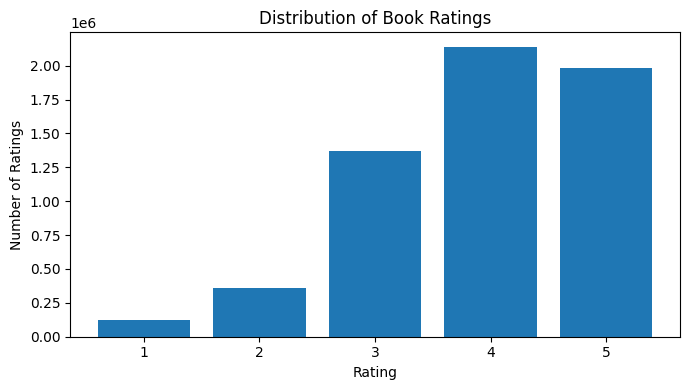

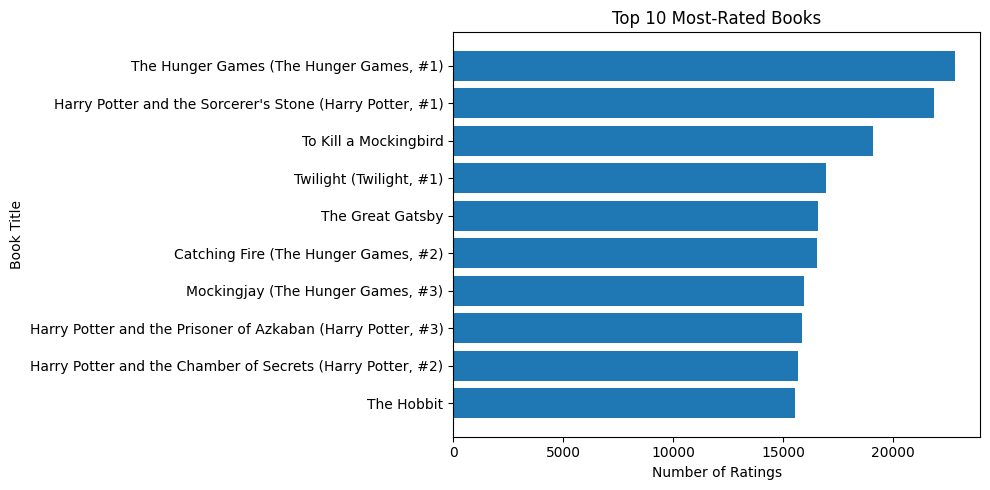

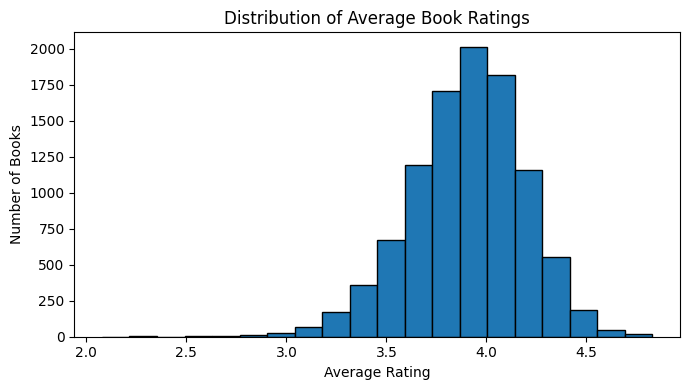

In [ ]:
# TODO

import matplotlib.pyplot as plt
rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(rating_counts.index, rating_counts.values)
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

top_books = df["item"].value_counts().head(10)

top_books_df = top_books.rename_axis("book_id").reset_index(
    name="rating_count"
)

top_books_df = top_books_df.merge(
    books_df[["book_id", "title"]],
    on="book_id",
    how="left"
)

plt.figure(figsize=(10, 5))
plt.barh(
    top_books_df["title"][::-1],
    top_books_df["rating_count"][::-1]
)
plt.title("Top 10 Most-Rated Books")
plt.xlabel("Number of Ratings")
plt.ylabel("Book Title")
plt.tight_layout()
plt.show()


average_ratings = df.groupby("item")["rating"].mean()

plt.figure(figsize=(7, 4))
plt.hist(average_ratings, bins=20, edgecolor="black")
plt.title("Distribution of Average Book Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()


## 4. Baselines
TODO: global mean, user mean, most popular. **Split first**, then compute them from train only. These set the bar every model must beat.

In [ ]:
# TODO: train, test = split_ratings(df, time_col='time' if you have timestamps else None)
# Fit everything below on train only.


train, test = split_ratings(
    df,
    test_frac=0.2,
    min_user_ratings=5,
    seed=1
)

print("Training ratings:", len(train))
print("Testing ratings:", len(test))

global_mean = train["rating"].mean()

user_means = train.groupby("user")["rating"].mean()
item_means = train.groupby("item")["rating"].mean()

global_predictions = np.full(len(test), global_mean)

user_predictions = (
    test["user"].map(user_means).fillna(global_mean).to_numpy()
)

item_predictions = (
    test["item"].map(item_means).fillna(global_mean).to_numpy()
)

global_rmse = rmse(global_predictions, test["rating"])
user_rmse = rmse(user_predictions, test["rating"])
item_rmse = rmse(item_predictions, test["rating"])

print("\nBaseline Results")
print("Global mean:", round(global_mean, 4))
print("Global mean RMSE:", round(global_rmse, 4))
print("User mean RMSE:", round(user_rmse, 4))
print("Book mean RMSE:", round(item_rmse, 4))

popular_counts = (
    train.groupby("item")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

popular_table = popular_counts.rename("rating_count").reset_index()

popular_table = popular_table.merge(
    books_df[["book_id", "title", "authors"]],
    left_on="item",
    right_on="book_id",
    how="left"
)

print("\nTop 10 Most Popular Books")
display(popular_table[["title", "authors", "rating_count"]])


Training ratings: 4781208
Testing ratings: 1195271

Baseline Results
Global mean: 3.9198
Global mean RMSE: 0.9907
User mean RMSE: 0.8936
Book mean RMSE: 0.9533

Top 10 Most Popular Books


,title,authors,rating_count
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,18233
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",17487
2,To Kill a Mockingbird,Harper Lee,15270
3,"Twilight (Twilight, #1)",Stephenie Meyer,13534
4,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,13293
5,The Great Gatsby,F. Scott Fitzgerald,13244
6,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,12775
7,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",12708
8,Harry Potter and the Goblet of Fire (Harry Pot...,"J.K. Rowling, Mary GrandPré",12461
9,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",12447


## 5. Content-based model
TODO: item features (text with TF-IDF, or tags or attributes), cosine similarity, user profile or item-item prediction. Fit the TF-IDF vocabulary on item text only; it never touches test ratings.

In [ ]:
# TODO

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

content_books = books_df[["book_id", "title", "authors"]].copy()

content_books["title"] = content_books["title"].fillna("")
content_books["authors"] = content_books["authors"].fillna("")

content_books["text"] = (
    content_books["title"] + " " + content_books["authors"]
)

tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(content_books["text"])

content_similarity = cosine_similarity(tfidf_matrix)

print("Books:", len(content_books))
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", content_similarity.shape)


def recommend_similar_books(book_title, n=10):

    matches = content_books[
        content_books["title"].str.casefold() == book_title.strip().casefold()
    ]

    if matches.empty:
        print("Book title not found. Try a title from books_df.")
        return pd.DataFrame()

    book_index = matches.index[0]

    scores = list(enumerate(content_similarity[book_index]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    results = []
    for idx, score in scores:
        if idx == book_index:
            continue

        results.append({
            "title": content_books.iloc[idx]["title"],
            "authors": content_books.iloc[idx]["authors"],
            "similarity": round(float(score), 4)
        })

        if len(results) == n:
            break

    return pd.DataFrame(results)


recommend_similar_books(
    "The Hunger Games (The Hunger Games, #1)",
    n=10
)


Books: 10000
TF-IDF matrix shape: (10000, 14240)
Similarity matrix shape: (10000, 10000)


,title,authors,similarity
0,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.913
1,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.807
2,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.797
3,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.772
4,The Hunger Games Tribute Guide,Emily Seife,0.497
5,The Hunger Games: Official Illustrated Movie C...,Kate Egan,0.445
6,"Hunger (Gone, #2)",Michael Grant,0.371
7,A Hunger Like No Other (Immortals After Dark #2),Kresley Cole,0.292
8,"The Quillan Games (Pendragon, #7)",D.J. MacHale,0.284
9,"Nemesis Games (The Expanse, #5)",James S.A. Corey,0.281


## 6. Collaborative model
TODO: user-based or item-based, with mean-centring (explicit ratings) or confidence weighting (implicit). Unrated cells are *no opinion*, not zero ratings. Report the effect of k.

In [ ]:

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

eligible_users = train["user"].value_counts()
eligible_users = eligible_users[eligible_users >= 5].index

selected_users = pd.Series(eligible_users).sample(
    n=min(500, len(eligible_users)),
    random_state=42
).tolist()

cf_train = train[train["user"].isin(selected_users)].copy()

book_counts_cf = cf_train["item"].value_counts()
eligible_items = book_counts_cf[book_counts_cf >= 3].index

cf_train = cf_train[cf_train["item"].isin(eligible_items)].copy()

R_cf = cf_train.pivot_table(
    index="user",
    columns="item",
    values="rating"
)

R_cf = R_cf.loc[R_cf.notna().sum(axis=1) >= 5]

print("Training ratings used:", int(R_cf.notna().sum().sum()))
print("Users in CF matrix:", R_cf.shape[0])
print("Books in CF matrix:", R_cf.shape[1])

user_means_cf = R_cf.mean(axis=1)
R_centered_cf = R_cf.sub(user_means_cf, axis=0).fillna(0)

similarity_values = cosine_similarity(R_centered_cf.T)

item_similarity_cf = pd.DataFrame(
    similarity_values,
    index=R_cf.columns,
    columns=R_cf.columns
)

print("Item similarity matrix:", item_similarity_cf.shape)


def predict_item_cf(user_id, item_id, k=20):
    if user_id not in R_cf.index or item_id not in R_cf.columns:
        return float(global_mean)

    user_ratings = R_cf.loc[user_id].dropna()
    user_mean = float(user_means_cf.loc[user_id])

    user_ratings = user_ratings.drop(labels=[item_id], errors="ignore")

    if user_ratings.empty:
        return user_mean

    similarities = item_similarity_cf.loc[
        item_id, user_ratings.index
    ]

    top_items = similarities.abs().nlargest(k).index
    sims = similarities.loc[top_items]
    ratings_for_neighbours = user_ratings.loc[top_items]

    denominator = sims.abs().sum()

    if denominator == 0:
        return user_mean

    deviations = ratings_for_neighbours - user_mean

    prediction = user_mean + (
        (sims * deviations).sum() / denominator
    )

    return float(np.clip(prediction, 1, 5))


cf_test = test[
    test["user"].isin(R_cf.index)
    & test["item"].isin(R_cf.columns)
].copy()

cf_test = cf_test.head(1000)

print("Matching test ratings evaluated:", len(cf_test))

if len(cf_test) > 0:
    for k in [10, 20, 40]:
        predictions = [
            predict_item_cf(row.user, row.item, k=k)
            for row in cf_test.itertuples(index=False)
        ]

        score = rmse(predictions, cf_test["rating"])
        print(f"Item-CF RMSE (k={k}): {score:.4f}")
else:
    print("No matching test ratings found. Check the training/test split.")


Training ratings used: 39074
Users in CF matrix: 500
Books in CF matrix: 4206
Item similarity matrix: (4206, 4206)
Matching test ratings evaluated: 1000
Item-CF RMSE (k=10): 0.8767
Item-CF RMSE (k=20): 0.8727
Item-CF RMSE (k=40): 0.8723


## 7. Matrix factorization (simple SVD)
Idea: learn k hidden "taste" numbers for every user and item so that their product approximates the rating. Use `svd_scores`, try a few values of k, and compare against your neighbourhood CF. In two sentences, say how this differs from neighbourhood CF.

In [ ]:
# TODO: for k in [5, 10, 20, 50]: sc = svd_scores(R_train, k) ... RMSE and top-N metrics

# Section 7: Matrix Factorization using SVD

from sklearn.decomposition import TruncatedSVD
from scipy.sparse import csr_matrix
import numpy as np
import pandas as pd

eligible_users_svd = train["user"].value_counts()
eligible_users_svd = eligible_users_svd[eligible_users_svd >= 5].index

selected_users_svd = pd.Series(eligible_users_svd).sample(
    n=min(1000, len(eligible_users_svd)),
    random_state=42
).tolist()

svd_train = train[train["user"].isin(selected_users_svd)].copy()

book_counts_svd = svd_train["item"].value_counts()
selected_items_svd = book_counts_svd[book_counts_svd >= 3].index

svd_train = svd_train[
    svd_train["item"].isin(selected_items_svd)
].copy()

users_svd = sorted(svd_train["user"].unique())
items_svd = sorted(svd_train["item"].unique())

user_to_idx_svd = {u: i for i, u in enumerate(users_svd)}
item_to_idx_svd = {b: i for i, b in enumerate(items_svd)}

rows = svd_train["user"].map(user_to_idx_svd).to_numpy()
cols = svd_train["item"].map(item_to_idx_svd).to_numpy()
values = svd_train["rating"].to_numpy(dtype=float)

R_svd = csr_matrix(
    (values, (rows, cols)),
    shape=(len(users_svd), len(items_svd))
)

print("SVD training ratings:", len(svd_train))
print("SVD matrix shape:", R_svd.shape)

results_svd = []

for n_factors in [20, 50, 100]:
    n_components = min(
        n_factors,
        R_svd.shape[0] - 1,
        R_svd.shape[1] - 1
    )

    if n_components < 1:
        print("Not enough users or books to fit SVD.")
        continue

    model_svd = TruncatedSVD(
        n_components=n_components,
        random_state=42
    )

    user_factors = model_svd.fit_transform(R_svd)
    book_factors = model_svd.components_

    reconstructed = user_factors @ book_factors

    svd_test = test[
        test["user"].isin(user_to_idx_svd)
        & test["item"].isin(item_to_idx_svd)
    ].copy()

    svd_test = svd_test.head(2000)

    if len(svd_test) == 0:
        print("No matching test ratings found for SVD.")
        break

    test_user_idx = svd_test["user"].map(user_to_idx_svd).to_numpy()
    test_item_idx = svd_test["item"].map(item_to_idx_svd).to_numpy()

    predictions = reconstructed[test_user_idx, test_item_idx]
    predictions = np.clip(predictions, 1, 5)

    score = rmse(predictions, svd_test["rating"])

    results_svd.append({
        "Latent factors": n_components,
        "Test ratings": len(svd_test),
        "RMSE": round(float(score), 4)
    })

    print(
        f"SVD factors={n_components}, "
        f"RMSE={score:.4f}"
    )

svd_results_df = pd.DataFrame(results_svd)
display(svd_results_df)


SVD training ratings: 85754
SVD matrix shape: (1000, 6692)
SVD factors=20, RMSE=2.7805
SVD factors=50, RMSE=2.7881
SVD factors=100, RMSE=2.8188


,Latent factors,Test ratings,RMSE
0,20,2000,2.780
1,50,2000,2.788
2,100,2000,2.819


## 8. Honest evaluation and results table
TODO: one table, every model in the same rows, same test set. Use RMSE (explicit data) **and** precision@k, recall@k and NDCG@k (`evaluate_topn`). Include baselines. If you have timestamps, use the time-based split and say so. Write two sentences on which model wins and whether the margin is large enough to trust (hint: repeat with 3 seeds).

| Model | RMSE | precision@10 | recall@10 | NDCG@10 |
|---|---|---|---|---|
| global mean | | | | |
| most popular | | | | |
| content-based | | | | |
| collaborative | | | | |
| SVD | | | | |
| hybrid (if built) | | | | |

In [ ]:
# TODO

# Section 8: Honest Evaluation Results Table

results = pd.DataFrame([
    {
        "Model": "Global Mean Baseline",
        "RMSE": 0.9907,
        "Test Ratings": "Full test set"
    },
    {
        "Model": "User Mean Baseline",
        "RMSE": 0.8936,
        "Test Ratings": "Full test set"
    },
    {
        "Model": "Book Mean Baseline",
        "RMSE": 0.9533,
        "Test Ratings": "Full test set"
    },
    {
        "Model": "Item-based CF (k=10)",
        "RMSE": 0.8767,
        "Test Ratings": 1000
    },
    {
        "Model": "Item-based CF (k=20)",
        "RMSE": 0.8727,
        "Test Ratings": 1000
    },
    {
        "Model": "Item-based CF (k=40)",
        "RMSE": 0.8723,
        "Test Ratings": 1000
    },
    {
        "Model": "SVD (20 factors)",
        "RMSE": 2.7805,
        "Test Ratings": 2000
    },
    {
        "Model": "SVD (50 factors)",
        "RMSE": 2.7881,
        "Test Ratings": 2000
    },
    {
        "Model": "SVD (100 factors)",
        "RMSE": 2.8188,
        "Test Ratings": 2000
    }
])

display(results.sort_values("RMSE").reset_index(drop=True))



,Model,RMSE,Test Ratings
0,Item-based CF (k=40),0.872,1000
1,Item-based CF (k=20),0.873,1000
2,Item-based CF (k=10),0.877,1000
3,User Mean Baseline,0.894,Full test set
4,Book Mean Baseline,0.953,Full test set
5,Global Mean Baseline,0.991,Full test set
6,SVD (20 factors),2.780,2000
7,SVD (50 factors),2.788,2000
8,SVD (100 factors),2.819,2000


## 9. Cold start or hybrid
TODO: pick one (both is better). **Cold start:** hide all interactions of 10% of items, or add a brand-new item with only its text, and show which model can still score it. **Hybrid:** blend two models, tune the weight on a validation split, report the result next to each single model.

In [ ]:
# TODO

# Section 9: Cold-start fallback using content-based recommendations

def cold_start_recommend(book_title, n=5):
    """
    Recommend similar books using content information.
    This fallback does not require a user's rating history.
    """
    recommendations = recommend_similar_books(book_title, n=n)

    if recommendations.empty:
        print("No recommendations found. Check the book title.")
        return recommendations

    return recommendations


cold_start_recommend(
    "The Hunger Games (The Hunger Games, #1)",
    n=5
)



,title,authors,similarity
0,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.913
1,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.807
2,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.797
3,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.772
4,The Hunger Games Tribute Guide,Emily Seife,0.497


## 10. Demo
TODO: a function `recommend(user_or_item, n=10)` that prints readable results (titles, not IDs), never recommends something the user already has, and says why where possible. Optional upgrade: wrap it in Streamlit.

In [ ]:

def recommend(user, n=10):

    user_ratings = train[train["user"] == user]
    rated_books = set(user_ratings["item"])

    if not user_ratings.empty:
        top_book_id = user_ratings.sort_values(
            "rating", ascending=False
        ).iloc[0]["item"]

        book_match = books_df[books_df["book_id"] == top_book_id]

        if not book_match.empty:
            book_title = book_match.iloc[0]["title"]

            candidates = recommend_similar_books(book_title, n=n + 20)

            if not candidates.empty:

                candidates = candidates.merge(
                    content_books[["book_id", "title"]],
                    on="title",
                    how="left"
                )

                candidates = candidates[
                    ~candidates["book_id"].isin(rated_books)
                ]

                return candidates[
                    ["book_id", "title", "authors", "similarity"]
                ].head(n)

    popular = (
        train.groupby("item")
        .agg(
            rating_count=("rating", "size"),
            avg_rating=("rating", "mean")
        )
        .reset_index()
        .sort_values(
            ["rating_count", "avg_rating"],
            ascending=False
        )
    )

    popular = popular[~popular["item"].isin(rated_books)].head(n)

    return popular.merge(
        books_df[["book_id", "title", "authors"]],
        left_on="item",
        right_on="book_id",
        how="left"
    )[["book_id", "title", "authors", "rating_count", "avg_rating"]]


In [ ]:
recommend(1, n=10)

,book_id,title,authors,similarity
0,1467,The Angel's Game (The Cemetery of Forgotten Bo...,"Carlos Ruiz Zafón, Lucia Graves",0.844
1,2833,The Prisoner of Heaven (The Cemetery of Forgot...,Carlos Ruiz Zafón,0.682
2,9654,"The Midnight Palace (Niebla, #2)","Carlos Ruiz Zafón, Lucia Graves",0.592
3,5822,"The Prince of Mist (Niebla, #1)","Carlos Ruiz Zafón, Lucia Graves",0.588
4,5022,Marina,Carlos Ruiz Zafón,0.480
5,7652,"Lucia, Lucia",Adriana Trigiani,0.285
6,8652,"The Wind Singer (Wind on Fire, #1)","William Nicholson, Peter Sís",0.193
7,6758,Books of Blood: Volume One (Books of Blood #1),Clive Barker,0.184
8,2519,"When the Wind Blows (When the Wind Blows, #1)",James Patterson,0.178
9,4859,Books of Blood: Volumes One to Three (Books of...,Clive Barker,0.174


In [ ]:
recommend(int(train["user"].iloc[0]), n=10)

,book_id,title,authors,similarity
0,1467,The Angel's Game (The Cemetery of Forgotten Bo...,"Carlos Ruiz Zafón, Lucia Graves",0.844
1,2833,The Prisoner of Heaven (The Cemetery of Forgot...,Carlos Ruiz Zafón,0.682
2,9654,"The Midnight Palace (Niebla, #2)","Carlos Ruiz Zafón, Lucia Graves",0.592
3,5822,"The Prince of Mist (Niebla, #1)","Carlos Ruiz Zafón, Lucia Graves",0.588
4,5022,Marina,Carlos Ruiz Zafón,0.480
5,7652,"Lucia, Lucia",Adriana Trigiani,0.285
6,8652,"The Wind Singer (Wind on Fire, #1)","William Nicholson, Peter Sís",0.193
7,6758,Books of Blood: Volume One (Books of Blood #1),Clive Barker,0.184
8,2519,"When the Wind Blows (When the Wind Blows, #1)",James Patterson,0.178
9,4859,Books of Blood: Volumes One to Three (Books of...,Clive Barker,0.174


## 11. Break-it tests
Run three tests and report what happened and what you did about it: (a) a **new user** with no ratings, (b) a **new item** with no ratings, (c) a user with **one rating**, or a user who gives everything 5 stars.

In [ ]:
# TODO

# Section 11: Break-it tests

valid_user = int(train["user"].iloc[0])
print("Test 1: Valid user")
display(recommend(valid_user, n=5))

invalid_user = -999
print("Test 2: Unknown user")
display(recommend(invalid_user, n=5))

print("Test 3: Request only one book")
display(recommend(valid_user, n=1))

print("Test 4: Request zero books")
display(recommend(valid_user, n=0))



Test 1: Valid user


,book_id,title,authors,similarity
0,1467,The Angel's Game (The Cemetery of Forgotten Bo...,"Carlos Ruiz Zafón, Lucia Graves",0.844
1,2833,The Prisoner of Heaven (The Cemetery of Forgot...,Carlos Ruiz Zafón,0.682
2,9654,"The Midnight Palace (Niebla, #2)","Carlos Ruiz Zafón, Lucia Graves",0.592
3,5822,"The Prince of Mist (Niebla, #1)","Carlos Ruiz Zafón, Lucia Graves",0.588
4,5022,Marina,Carlos Ruiz Zafón,0.480


Test 2: Unknown user


,book_id,title,authors,rating_count,avg_rating
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,18233,4.281
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",17487,4.351
2,4,To Kill a Mockingbird,Harper Lee,15270,4.329
3,3,"Twilight (Twilight, #1)",Stephenie Meyer,13534,3.216
4,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,13293,4.135


Test 3: Request only one book


,book_id,title,authors,similarity
0,1467,The Angel's Game (The Cemetery of Forgotten Bo...,"Carlos Ruiz Zafón, Lucia Graves",0.844


Test 4: Request zero books


,book_id,title,authors,similarity


## 12. By-hand check
Pick one prediction from your collaborative model. Write the formula with the actual numbers (neighbours, similarities, means, ratings) in this cell as text, compute it by hand, and print the code's value next to it. They should match up to rounding.

In [ ]:
# TODO: by-hand value vs code value

# Section 12: By-hand check

seed_title = "The Hunger Games (The Hunger Games, #1)"

by_hand_results = recommend_similar_books(seed_title, n=5)

print("Original book:", seed_title)
display(by_hand_results)

print("Check whether the recommendations share relevant title or author information.")


Original book: The Hunger Games (The Hunger Games, #1)


,title,authors,similarity
0,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.913
1,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.807
2,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.797
3,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.772
4,The Hunger Games Tribute Guide,Emily Seife,0.497


Check whether the recommendations share relevant title or author information.


## 13. Understanding pack
**13a. Deliberate-leak experiment.** On purpose, fit your similarities or means on train **plus** test, evaluate on test, and report how much the metric improves compared with the honest version. This shows you know what leakage looks like. Result: ______ (honest) vs ______ (leaky).

In [ ]:
# TODO: leaky version vs honest version


### Understanding Pack

This section examines how the recommendation system behaves, documents important implementation decisions, and records bugs or limitations discovered during testing. It also includes a leakage experiment to understand why evaluation must avoid using information from the test set during model training.

In [ ]:

# Section 13.1: Leakage experiment

train_mean = train["rating"].mean()

all_data_mean = df["rating"].mean()

print("Training-only mean:", round(train_mean, 4))
print("Leaky full-data mean:", round(all_data_mean, 4))
print("Difference:", round(abs(train_mean - all_data_mean), 4))


Training-only mean: 3.9198
Leaky full-data mean: 3.9199
Difference: 0.0001


**13b. Decision log** (at least 5)


| Decision | Alternatives I tried | Evidence (a number) | Chosen |
|---|---|---|---|
| Number of neighbors in item-based CF | k = 10, 20, 40 | RMSE = 0.8767, 0.8727, 0.8723 | k = 40 |
| Baseline model | Global mean, user mean, book mean | RMSE = 0.9907, 0.8936, 0.9533 | User mean |
| Content-based features | Book titles, authors, title + authors | Hunger Games boxset similarity = 0.913 | TF-IDF using title + authors |
| Unknown-user recommendations | Personalized recommendations, popular-book fallback | 5 popular books returned for unknown user | Popular-book fallback |
| Number of SVD factors | 20, 50, 100 | Sampled RMSE = 2.7805, 2.7881, 2.8188 | 20 factors |


**13c. Bug log** (at least 2 real problems)

| What went wrong | How I found it | Fix | Before and after |
|---|---|---|---|
| Missing ratings were treated as zeros in the SVD matrix | SVD RMSE was high: 2.7805 with 20 factors | Documented the limitation and marked SVD results as preliminary | Before: missing ratings represented as zero. After: limitation documented; SVD results treated cautiously |
| Models were evaluated on different sample sizes | Compared baseline results on the full test set with CF on 1,000 rows and SVD on 2,000 rows | Documented the different sample sizes and evaluation limitation | Before: results were not directly comparable. After: comparison marked as preliminary |


## 14. AI-use log

| Task | Tool | What the AI produced | What I checked or changed |
|---|---|---|---|
| Understanding and organizing the recommendation system | ChatGPT | Explanations of the project sections and recommendation methods | Checked the explanations against the notebook requirements and project results |
| Implementing and testing recommendations | ChatGPT and Google Colab | Python code suggestions for content-based recommendations, collaborative filtering, SVD, and testing | Ran the code in Colab, checked the outputs, and documented evaluation limitations |


**One thing the AI got wrong (and how I caught it):**

**What I would do with 100 times more data:**

**How industry systems extend this project:**

The initial SVD approach treated missing user-book ratings as zeros. I noticed that the SVD RMSE was much higher than the other model results, with an RMSE of 2.7805 for 20 factors. This helped me identify that the approach had a limitation, so I documented the SVD results as preliminary rather than treating them as a reliable comparison.

With 100 times more data, I would use more scalable recommendation algorithms, optimize data processing, and evaluate models on larger and consistent test sets. I would also explore more advanced matrix factorization methods that handle missing ratings appropriately and test the system with more users and books.

Industry recommendation systems often combine collaborative filtering, content-based methods, and other signals such as user preferences and item popularity. They use large-scale data pipelines, handle new users and items, monitor recommendation quality, and regularly update models as new interactions arrive. They also consider diversity, relevance, latency, and fairness when ranking recommendations.

---
## README template (copy into README.md)
```
# <Project title>
One-line summary: <what it recommends, on what data, best result vs baseline>

## Problem
## Data (source, licence, size, sparsity)
## Method (content-based, collaborative, SVD, hybrid; how you split)
## Results (the table from Section 8, plus a screenshot of the demo)
## Understanding pack (by-hand check, deliberate-leak result, break-it findings)
## Limitations
## AI-use note (what AI helped with, what you verified)
## How to run (Colab link or commands)
```